# 05. Product friction and customer campaigns

The same estimators on two more problems with the same shape: a treatment
that reacts to a customer's state and changes it.

- **Friction and churn:** failed payments, card declines, app errors and
  re-verification checks lower engagement, and engagement drives both later
  friction and churn.
- **Campaigns and take-up:** a CRM rule targets emails and pushes on an
  engagement score, and the campaigns move interest and fatigue, which move
  the score.

In both, the count regression gets the sign wrong (the "before event, or
all" version is shown; the others are worse). Customers who churn or take
up early have fewer weeks in which to be treated. A boosted model read
with SHAP, the usual driver analysis, ranks the types wrongly and gets
some directions backwards for the same reasons.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

from gmethods import (
    LTMLE, CampaignScenario, CampaignSimulator, CountRegression,
    FrictionScenario, FrictionSimulator, PooledHazard,
)
from gmethods import interventions as iv
from gmethods.attribution import attribute_marginal, marginal_from_risks
from gmethods.estimators import ShapDrivers

sys.path.insert(0, str(Path("..").resolve() / "tools"))
from recovery_weekly import summarise

pd.set_option("display.width", 120)

In [2]:
import matplotlib.pyplot as plt

# Reference categorical palette, fixed order. Truth is drawn in ink.
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "legend.frameon": False,
})

## Friction and churn

In [3]:
sim = FrictionSimulator(FrictionScenario.preset("baseline"))
data = sim.simulate(n=50_000, seed=1)
spec = sim.panel_spec()
regimes = iv.standard_set(sim.LEVELS) + iv.scale_set(sim.LEVELS, factor=0.9)[1:]
truth = pd.read_csv("../results/truth_friction.csv", index_col="regime")
print(f"churn per 1,000 customers: {truth.loc['natural_course', 'risk'] * 1000:.1f}")
model = LTMLE(spec).fit(data.panel)
rd = pd.DataFrame({
    "truth": truth["rd"],
    "count, before event or all": CountRegression.for_simulator(
        sim, "before_complaint_or_all").fit(data.customers).estimate(regimes).to_frame()["rd"],
    "pooled hazard": PooledHazard(spec).fit(data.panel).estimate(regimes).to_frame()["rd"],
    "LTMLE": model.estimate(regimes).to_frame()["rd"],
}).drop(index="natural_course") * 1000
rd.round(2)

churn per 1,000 customers: 86.6


,truth,"count, before event or all",pooled hazard,LTMLE
regime,,,,
never_payment_failure,-1.15,3.15,-0.72,-1.28
never_card_decline,-0.68,4.32,-0.27,-0.71
never_app_error,-1.36,21.80,-0.27,-1.15
never_reverification,-5.54,30.68,-2.55,-6.10
never_any,-8.04,72.15,-3.77,-9.20
scale_payment_failure_0.9,-0.11,0.26,-0.07,-0.12
scale_card_decline_0.9,-0.07,0.34,-0.03,-0.06
scale_app_error_0.9,-0.14,1.53,-0.03,-0.12
scale_reverification_0.9,-0.10,2.19,-0.25,-0.40


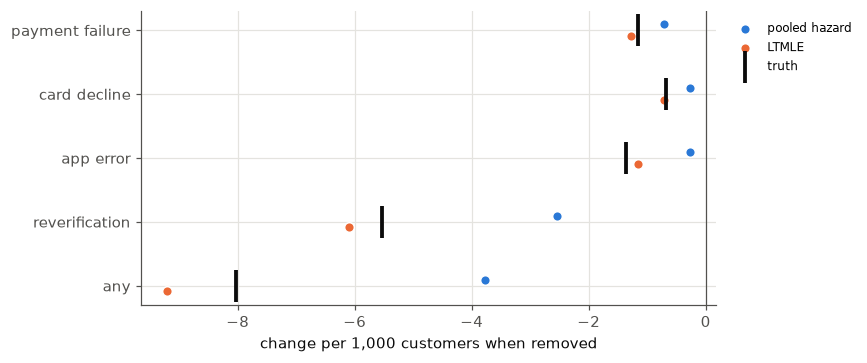

In [4]:
shown = [r for r in rd.index if r.startswith("never_")]
fig, ax = plt.subplots(figsize=(8, 3.4))
y = np.arange(len(shown))
for j, name in enumerate(["pooled hazard", "LTMLE"]):
    ax.scatter(rd.loc[shown, name], y + (j - 0.5) * 0.18, s=40, color=SERIES[j],
               edgecolor="white", linewidth=1, label=name, zorder=3)
ax.scatter(rd.loc[shown, "truth"], y, marker="|", s=450, color=INK, lw=2.5,
           label="truth", zorder=4)
ax.set_yticks(y, [s.removeprefix("never_").replace("_", " ") for s in shown])
ax.invert_yaxis()
ax.axvline(0, color=MUTED, lw=0.8)
ax.set_xlabel("change per 1,000 customers when removed")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
plt.tight_layout()

The marginal split: what each type changes if it were 10% rarer than today,
next to what a model-plus-SHAP driver analysis would report.

In [5]:
split = attribute_marginal(model, factor=0.9, names=sim.LEVELS)
true_split = marginal_from_risks(truth["risk"].to_dict(), factor=0.9, names=sim.LEVELS)
shap_drivers = ShapDrivers.for_simulator(sim).fit(data.customers).drivers()
types = list(sim.LEVELS[1:])
pd.DataFrame({
    "true share": true_split.loc[types, "share"],
    "LTMLE share": split.loc[types, "share"],
    "SHAP share": shap_drivers["share"],
    "SHAP direction": np.sign(shap_drivers["mean_shap_when_present"]).map(
        {1.0: "raises churn", -1.0: "lowers churn"}),
}).round(2)

,true share,LTMLE share,SHAP share,SHAP direction
payment_failure,0.27,0.17,0.05,lowers churn
card_decline,0.16,0.09,0.38,raises churn
app_error,0.33,0.17,0.27,lowers churn
reverification,0.23,0.57,0.30,lowers churn


## Campaigns and take-up

In [6]:
sim = CampaignSimulator(CampaignScenario.preset("baseline"))
data = sim.simulate(n=50_000, seed=1)
spec = sim.panel_spec()
regimes = iv.standard_set(sim.LEVELS) + iv.scale_set(sim.LEVELS, factor=0.9)[1:]
truth = pd.read_csv("../results/truth_campaign.csv", index_col="regime")
print(f"take-up per 1,000 customers: {truth.loc['natural_course', 'risk'] * 1000:.1f}")
model = LTMLE(spec).fit(data.panel)
rd = pd.DataFrame({
    "truth": truth["rd"],
    "count, before event or all": CountRegression.for_simulator(
        sim, "before_complaint_or_all").fit(data.customers).estimate(regimes).to_frame()["rd"],
    "pooled hazard": PooledHazard(spec).fit(data.panel).estimate(regimes).to_frame()["rd"],
    "LTMLE": model.estimate(regimes).to_frame()["rd"],
}).drop(index="natural_course") * 1000
rd.round(2)

take-up per 1,000 customers: 115.1


,truth,"count, before event or all",pooled hazard,LTMLE
regime,,,,
never_email_info,-5.70,88.63,-4.52,-5.29
never_email_offer,-8.28,47.60,-5.38,-6.69
never_push,-1.95,73.82,-2.18,-1.85
never_any,-17.02,314.04,-11.69,-13.86
scale_email_info_0.9,-0.58,5.62,-0.45,-0.52
scale_email_offer_0.9,-0.80,3.33,-0.55,-0.71
scale_push_0.9,-0.19,4.75,-0.22,-0.21
scale_any_0.9,-1.59,14.25,-1.21,-1.44


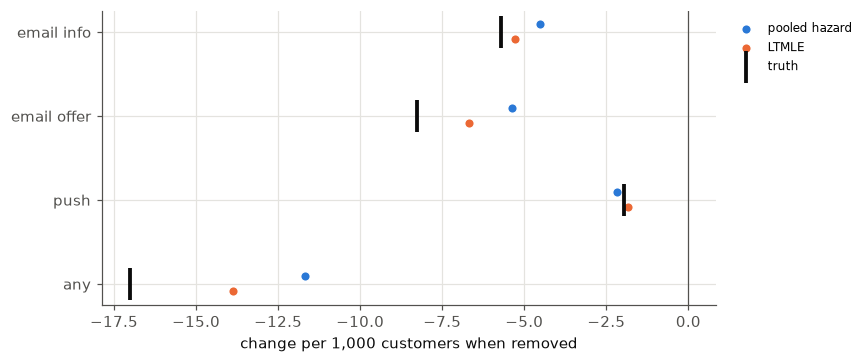

In [7]:
shown = [r for r in rd.index if r.startswith("never_")]
fig, ax = plt.subplots(figsize=(8, 3.4))
y = np.arange(len(shown))
for j, name in enumerate(["pooled hazard", "LTMLE"]):
    ax.scatter(rd.loc[shown, name], y + (j - 0.5) * 0.18, s=40, color=SERIES[j],
               edgecolor="white", linewidth=1, label=name, zorder=3)
ax.scatter(rd.loc[shown, "truth"], y, marker="|", s=450, color=INK, lw=2.5,
           label="truth", zorder=4)
ax.set_yticks(y, [s.removeprefix("never_").replace("_", " ") for s in shown])
ax.invert_yaxis()
ax.axvline(0, color=MUTED, lw=0.8)
ax.set_xlabel("change per 1,000 customers when removed")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
plt.tight_layout()

The marginal split: what each type changes if it were 10% rarer than today,
next to what a model-plus-SHAP driver analysis would report.

In [8]:
split = attribute_marginal(model, factor=0.9, names=sim.LEVELS)
true_split = marginal_from_risks(truth["risk"].to_dict(), factor=0.9, names=sim.LEVELS)
shap_drivers = ShapDrivers.for_simulator(sim).fit(data.customers).drivers()
types = list(sim.LEVELS[1:])
pd.DataFrame({
    "true share": true_split.loc[types, "share"],
    "LTMLE share": split.loc[types, "share"],
    "SHAP share": shap_drivers["share"],
    "SHAP direction": np.sign(shap_drivers["mean_shap_when_present"]).map(
        {1.0: "raises take-up", -1.0: "lowers take-up"}),
}).round(2)

,true share,LTMLE share,SHAP share,SHAP direction
email_info,0.37,0.36,0.18,raises take-up
email_offer,0.51,0.49,0.38,lowers take-up
push,0.12,0.14,0.44,lowers take-up


## Recovery across datasets

Ten datasets of 50,000 customers each. Regenerate with
`uv run python tools/recovery_weekly.py --sim friction --reps 10` (and
`--sim campaign`).

In [9]:
for name in ["friction", "campaign"]:
    out = summarise(name).xs("ltmle", level="estimator")
    out = out[["rd_true", "rd_mean", "sd"]].mul(1000).join(out[["coverage", "reps"]])
    print(name)
    display(out.round(3))

friction


,rd_true,rd_mean,sd,coverage,reps
regime,,,,,
never_any,-8.037,-8.871,2.345,0.5,10
never_app_error,-1.362,-1.342,0.961,0.9,10
never_card_decline,-0.677,-0.703,0.281,1.0,10
never_payment_failure,-1.155,-1.196,0.283,1.0,10
never_reverification,-5.540,-5.659,1.165,0.9,10
scale_any_0.9,-0.416,-0.488,0.318,0.9,10
scale_app_error_0.9,-0.138,-0.139,0.096,0.8,10
scale_card_decline_0.9,-0.068,-0.070,0.031,1.0,10
scale_payment_failure_0.9,-0.115,-0.116,0.026,1.0,10


campaign


,rd_true,rd_mean,sd,coverage,reps
regime,,,,,
never_any,-17.024,-15.266,6.438,1.0,10
never_email_info,-5.702,-6.449,1.734,1.0,10
never_email_offer,-8.276,-7.961,0.873,1.0,10
never_push,-1.952,-2.125,1.252,1.0,10
scale_any_0.9,-1.587,-1.587,0.212,0.9,10
scale_email_info_0.9,-0.581,-0.608,0.157,0.9,10
scale_email_offer_0.9,-0.804,-0.792,0.083,1.0,10
scale_push_0.9,-0.194,-0.178,0.095,1.0,10
